# Actividad 1 — EDA, limpieza y viabilidad · HousingPulse AI
Notebook de exploración del CSV de Miami-Dade (RealEstateDataset, 2026-10). Se ejecuta de arriba abajo desde la carpeta `notebooks/`.
Antes de ejecutarlo: colocar el CSV en `data/raw/` y lanzar `python src/clean_data.py` (genera `data/processed/housing_clean.csv`).

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight"})

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data/raw/realestatedataset-miami-dade-county-fl-2026-10.csv"
CLEAN = ROOT / "data/processed/housing_clean.csv"
FIG = ROOT / "reports/figures"; FIG.mkdir(parents=True, exist_ok=True)
def save(name): plt.savefig(FIG / f"{name}.png"); plt.show()

raw = pd.read_csv(RAW, low_memory=False)
raw["sale_dt"] = pd.to_datetime(raw["last_sold_date"], errors="coerce")
raw["sale_year"] = raw["sale_dt"].dt.year
print(f"{raw.shape[0]:,} filas x {raw.shape[1]} columnas")

1,015,955 filas x 32 columnas


## 1. Estructura y calidad del CSV original

In [2]:
info = pd.DataFrame({"dtype": raw.dtypes.astype(str), "nulos_%": (raw.isna().mean()*100).round(1),
                     "valores_distintos": raw.nunique()})
display(info)
print("Filas duplicadas completas:", raw.duplicated().sum(), "| ids duplicados:", raw["id"].duplicated().sum())
print("Inmuebles repetidos (calle+unidad+zip):", raw.duplicated(["street","unit","zip"]).sum())

,dtype,nulos_%,valores_distintos
id,str,0.0,1015955
street,str,0.0,987576
unit,str,89.3,17892
city,str,0.0,267
state,str,0.0,4
zip,float64,0.0,88
lat,float64,0.0,257883
lng,float64,0.0,123521
property_type,str,0.0,8
beds,float64,3.4,31


Filas duplicadas completas: 0 | ids duplicados: 0
Inmuebles repetidos (calle+unidad+zip): 21507


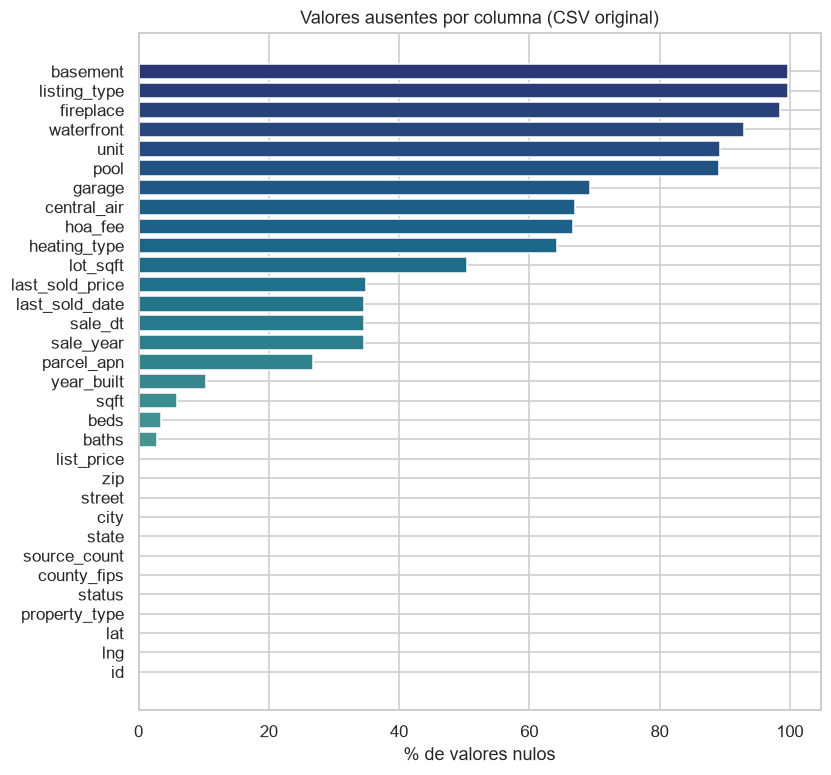

In [3]:
nulos = (raw.isna().mean()*100).sort_values()
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(nulos.index, nulos.values, color=sns.color_palette("crest", len(nulos)))
ax.set(xlabel="% de valores nulos", title="Valores ausentes por columna (CSV original)"); save("01_nulos")

## 2. Distribuciones

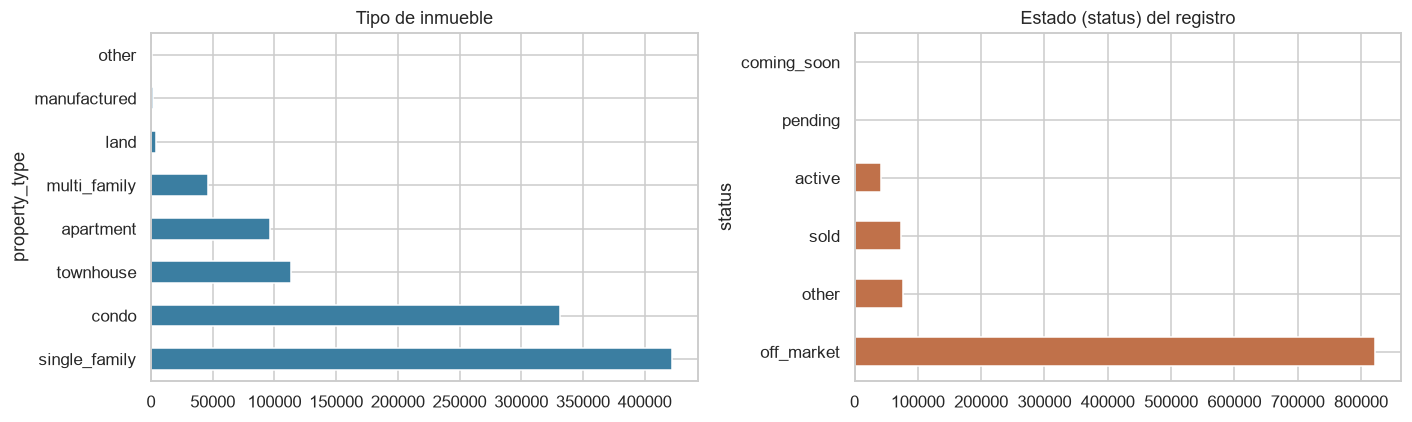

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
raw["property_type"].value_counts().plot.barh(ax=axes[0], color="#3b7ea1"); axes[0].set(title="Tipo de inmueble")
raw["status"].value_counts().plot.barh(ax=axes[1], color="#c0714a"); axes[1].set(title="Estado (status) del registro")
plt.tight_layout(); save("02_tipo_y_estado")

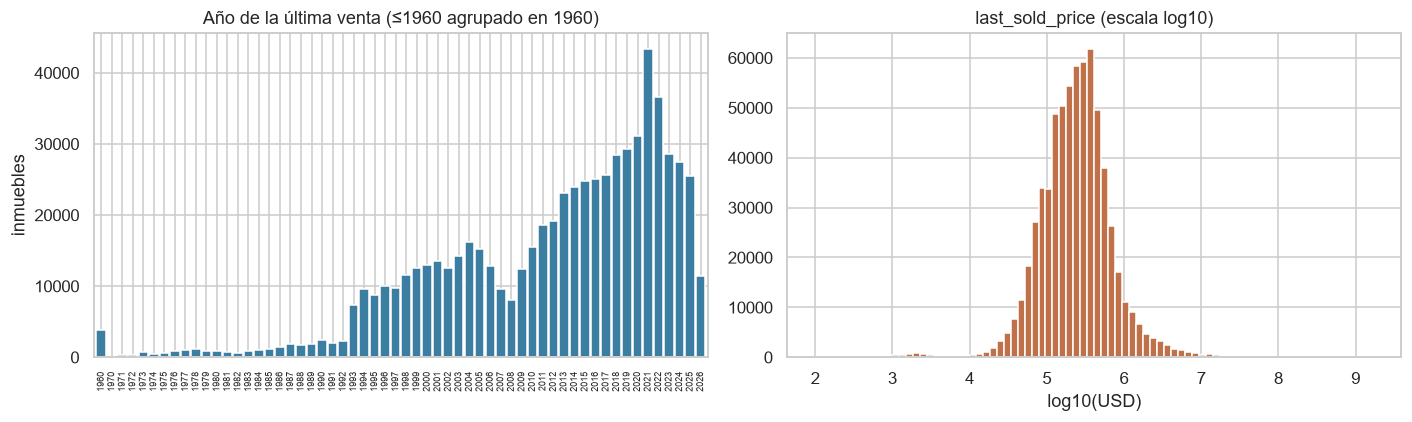

Fechas 1900-01-01 (relleno): 3841
Ventas desde 2025: 36980


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
raw["sale_year"].dropna().astype(int).clip(lower=1960).value_counts().sort_index().plot.bar(ax=axes[0], color="#3b7ea1", width=.9)
axes[0].set(title="Año de la última venta (≤1960 agrupado en 1960)", xlabel="", ylabel="inmuebles"); axes[0].tick_params(axis="x", labelsize=6)
sold = raw["last_sold_price"].dropna(); sold = sold[sold > 0]
axes[1].hist(np.log10(sold), bins=80, color="#c0714a"); axes[1].set(title="last_sold_price (escala log10)", xlabel="log10(USD)")
plt.tight_layout(); save("03_fecha_y_precio")
print("Fechas 1900-01-01 (relleno):", (raw["last_sold_date"] == "1900-01-01").sum())
print("Ventas desde 2025:", (raw["sale_dt"] >= "2025-01-01").sum())

,count,mean,std,min,1%,50%,99%,max
beds,981454.0,2.7,1.3,0.0,0.0,3.0,6.0,9.600000e+01
baths,986433.0,2.1,1.1,0.0,1.0,2.0,6.0,3.000000e+02
sqft,955416.0,1627.3,1991.0,0.0,396.0,1382.0,5634.0,7.227770e+05
year_built,911455.0,1981.0,23.8,70.0,1926.0,1980.0,2024.0,2.028000e+03
last_sold_price,660888.0,464517.9,2495013.4,0.0,15500.0,245000.0,4250000.0,1.700000e+09
list_price,1015892.0,716317.2,1917655.6,0.0,0.0,470000.0,5827318.0,2.370000e+08


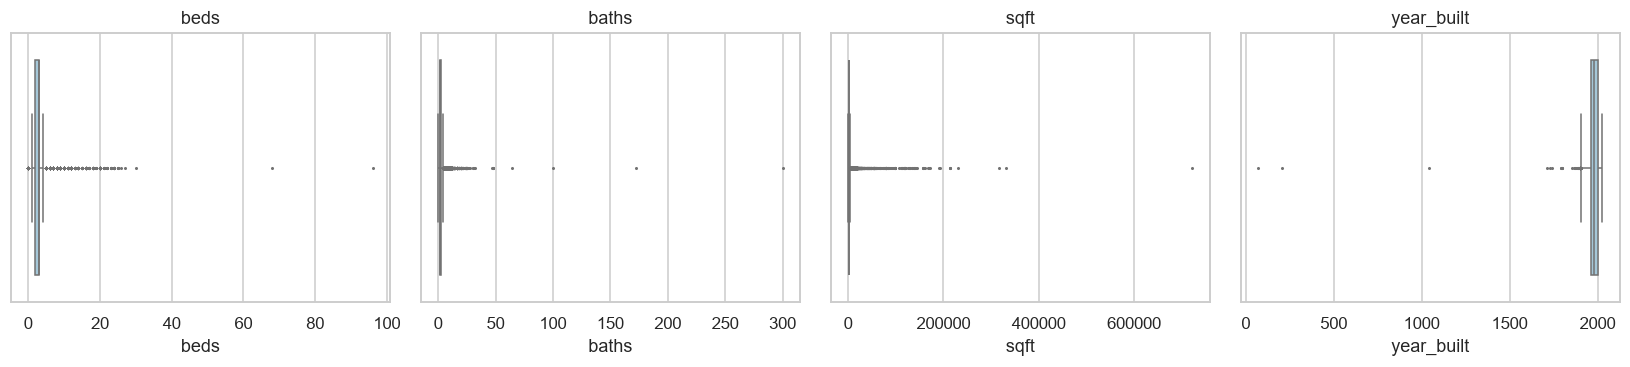

In [6]:
num = ["beds", "baths", "sqft", "year_built", "last_sold_price", "list_price"]
display(raw[num].describe(percentiles=[.01, .5, .99]).T.round(1))
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, c in zip(axes, ["beds", "baths", "sqft", "year_built"]):
    sns.boxplot(x=raw[c], ax=ax, color="#9ccae0", fliersize=1); ax.set_title(c)
plt.tight_layout(); save("04_outliers_originales")

## 3. Resultado de la limpieza (`src/clean_data.py`)

,paso,filas,eliminadas
0,CSV original,1015955,0
1,Solo FL y condado 12086,1015948,7
2,Solo tipos residenciales,1011063,4885
3,Con precio y fecha de venta,659575,351488
4,Fecha de venta valida,659234,341
5,Ventas desde 2025-01-01,36876,622358
6,"Precio de venta entre 20,000 y 30,000,000",36598,278
7,sqft en rango,36376,222
8,beds en rango,36328,48
9,baths en rango,36282,46


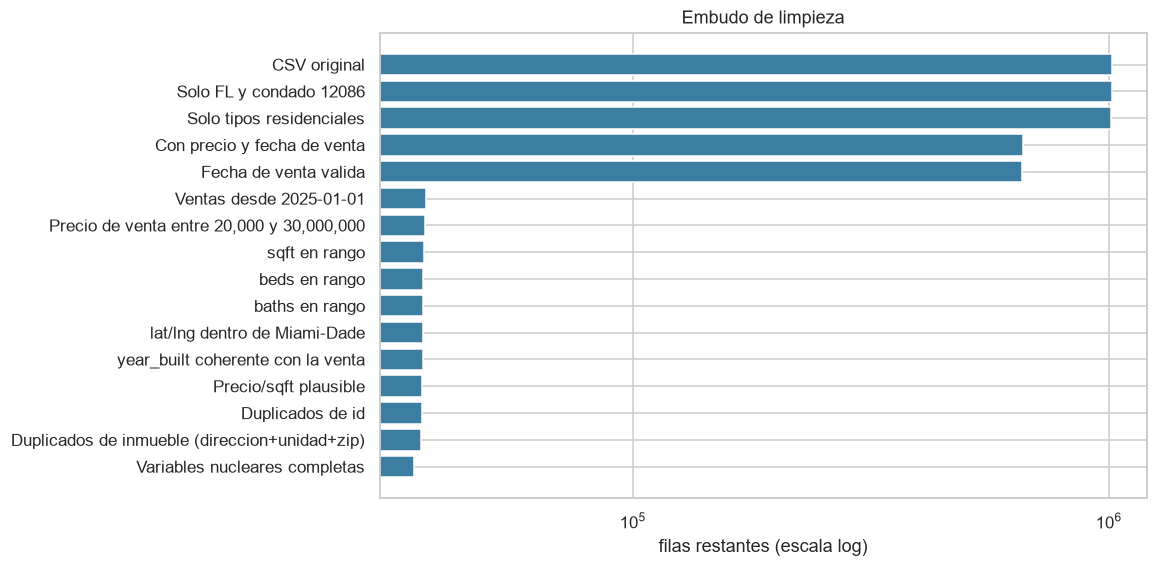

In [7]:
rep = json.loads((ROOT / "reports/cleaning_report.json").read_text(encoding="utf-8"))
fun = pd.DataFrame(rep["pasos"]); display(fun)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(fun["paso"][::-1], fun["filas"][::-1], color="#3b7ea1"); ax.set_xscale("log")
ax.set(xlabel="filas restantes (escala log)", title="Embudo de limpieza"); save("05_embudo_limpieza")

In [8]:
df = pd.read_csv(CLEAN, parse_dates=["sale_date"])
print(df.shape); display(df.head(3).drop(columns=["id"]))
display(df.describe().T.round(1))
print("Nulos restantes:", int(df.isna().sum().sum()), "(solo lot_sqft/hoa_fee, no nucleares)")
print(df.isna().sum()[df.isna().sum() > 0].to_dict())

(34793, 24)


,city,zip,lat,lng,property_type,beds,baths,sqft,lot_sqft,year_built,...,hoa_fee,pool,garage,waterfront,fireplace,basement,sale_date,sale_year,sale_month,property_age_at_sale
0,South Miami,33143,25.698403,-80.297822,single_family,4,2.0,1582.0,11250.0,1950,...,NaN,True,True,False,False,False,2025-01-01,2025,1,75
1,Miami Gardens,33169,25.945007,-80.216591,single_family,2,1.0,1044.0,9085.0,1956,...,NaN,True,False,False,False,False,2025-01-01,2025,1,69
2,Palmetto Bay,33157,25.609978,-80.320496,single_family,4,3.0,3034.0,14985.0,2003,...,NaN,True,True,False,False,False,2025-01-01,2025,1,22


,count,mean,min,25%,50%,75%,max,std
zip,34793.0,33130.86207,33010.0,33129.0,33147.0,33174.0,33610.0,56.781314
lat,34793.0,25.759806,25.381218,25.682587,25.770456,25.870723,25.9879,0.137713
lng,34793.0,-80.289005,-80.6224,-80.375186,-80.291765,-80.19253,-80.119316,0.106881
beds,34793.0,2.980571,0.0,2.0,3.0,4.0,12.0,1.294021
baths,34793.0,2.374949,1.0,2.0,2.0,3.0,10.0,1.112891
sqft,34793.0,1702.057224,200.0,1092.0,1486.0,2006.0,15906.0,1001.956178
lot_sqft,19176.0,11951.461149,0.0,5250.0,7500.0,9667.0,3484800.0,65794.423309
year_built,34793.0,1981.851982,1900.0,1961.0,1981.0,2004.0,2026.0,25.122794
sold_price,34793.0,940096.430115,38000.0,380000.0,552000.0,827500.0,30000000.0,1651115.199196
hoa_fee,17491.0,761.280201,1.0,205.0,402.0,860.0,21095.0,1155.005695


Nulos restantes: 32919 (solo lot_sqft/hoa_fee, no nucleares)
{'lot_sqft': 15617, 'hoa_fee': 17302}


## 4. EDA sobre el dataset limpio (ventas desde 2025)

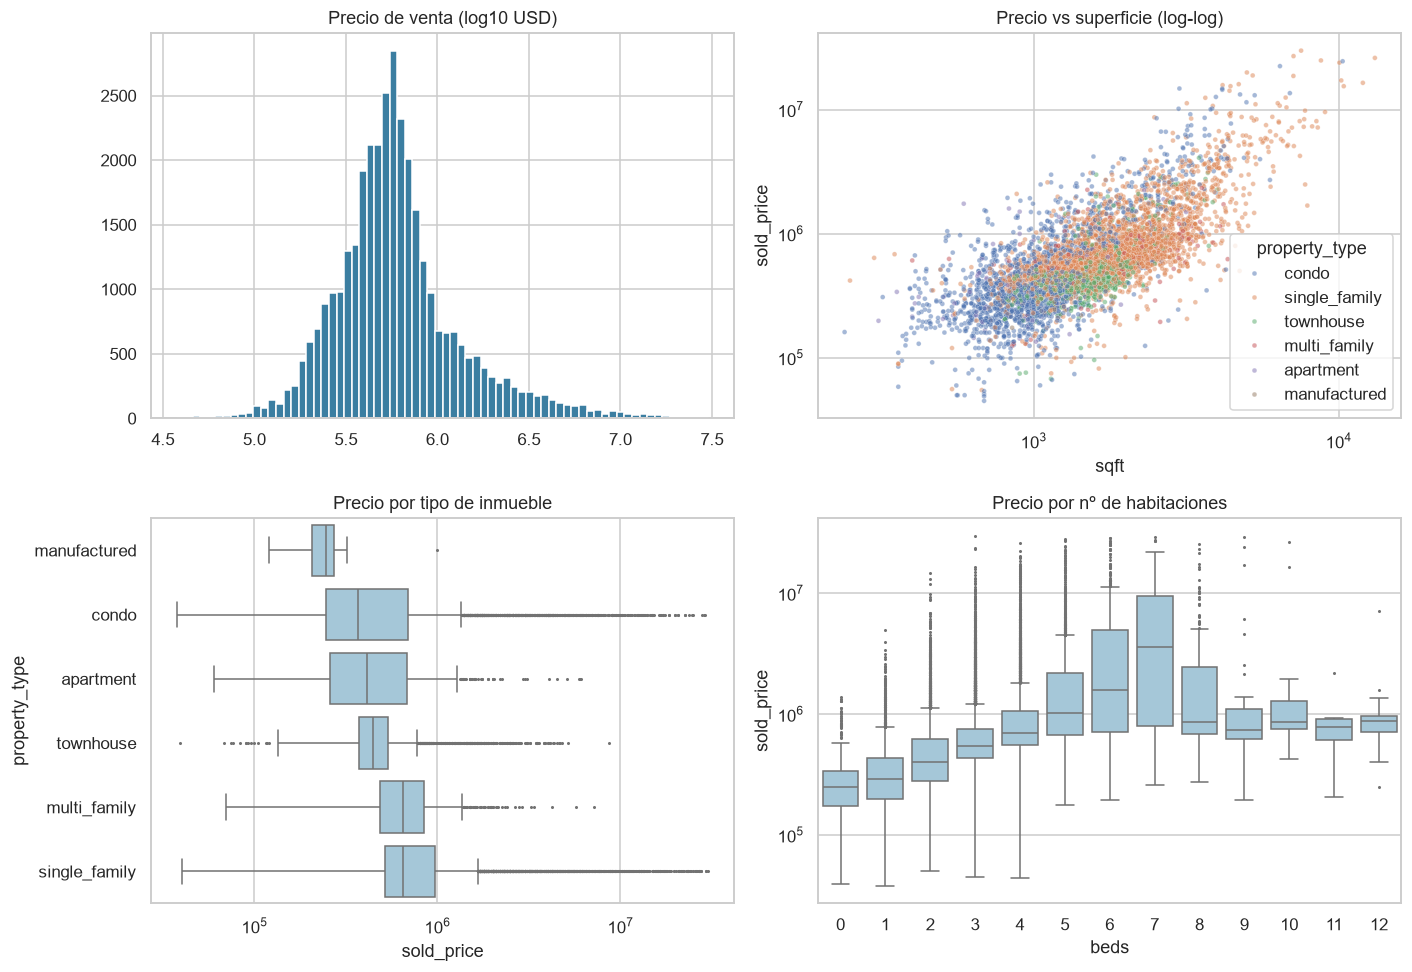

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes[0,0].hist(np.log10(df["sold_price"]), bins=70, color="#3b7ea1"); axes[0,0].set(title="Precio de venta (log10 USD)")
sns.scatterplot(data=df.sample(6000, random_state=0), x="sqft", y="sold_price", hue="property_type", s=10, alpha=.5, ax=axes[0,1])
axes[0,1].set(xscale="log", yscale="log", title="Precio vs superficie (log-log)")
order = df.groupby("property_type")["sold_price"].median().sort_values().index
sns.boxplot(data=df, y="property_type", x="sold_price", order=order, ax=axes[1,0], color="#9ccae0", fliersize=1)
axes[1,0].set(xscale="log", title="Precio por tipo de inmueble")
sns.boxplot(data=df, x="beds", y="sold_price", ax=axes[1,1], color="#9ccae0", fliersize=1)
axes[1,1].set(yscale="log", title="Precio por nº de habitaciones")
plt.tight_layout(); save("06_precio_relaciones")

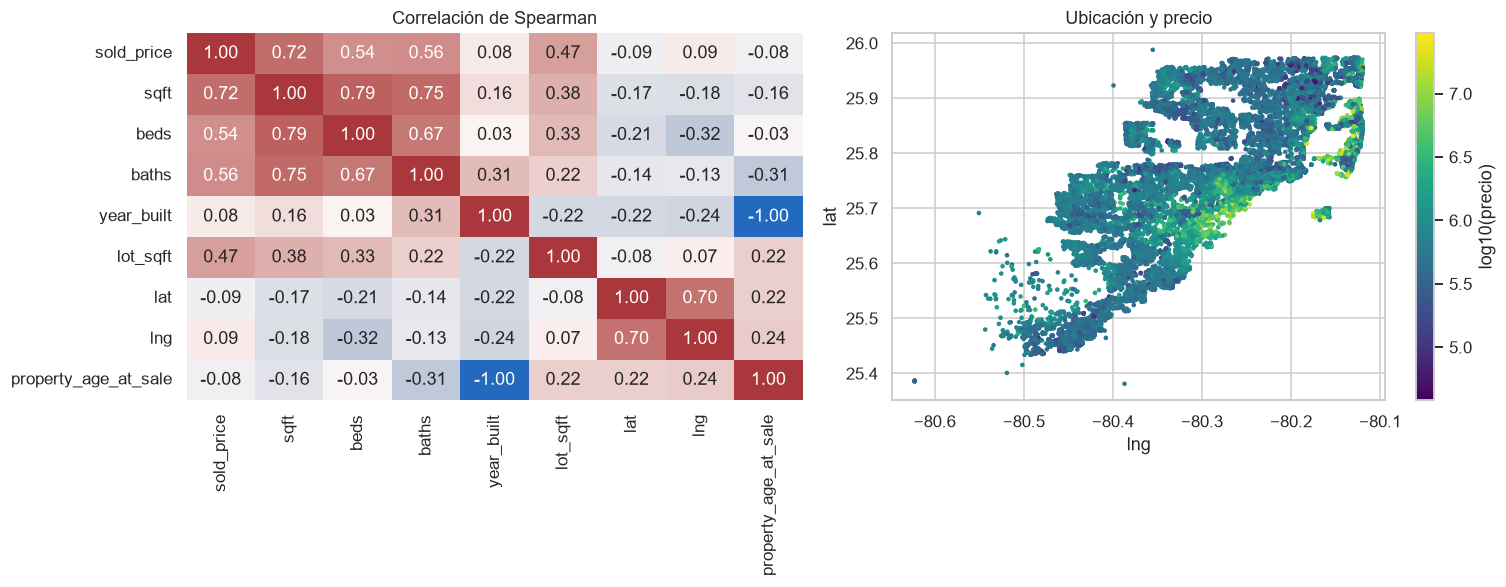

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
corr = df[["sold_price", "sqft", "beds", "baths", "year_built", "lot_sqft", "lat", "lng", "property_age_at_sale"]].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[0], cbar=False); axes[0].set_title("Correlación de Spearman")
s = df.sample(min(15000, len(df)), random_state=0)
sc = axes[1].scatter(s["lng"], s["lat"], c=np.log10(s["sold_price"]), s=4, cmap="viridis")
plt.colorbar(sc, ax=axes[1], label="log10(precio)"); axes[1].set(title="Ubicación y precio", xlabel="lng", ylabel="lat")
plt.tight_layout(); save("07_correlacion_y_mapa")

Códigos postales: 79 | con ≥30 ventas: 77 | ventas en los 10 zips más frecuentes: 27%


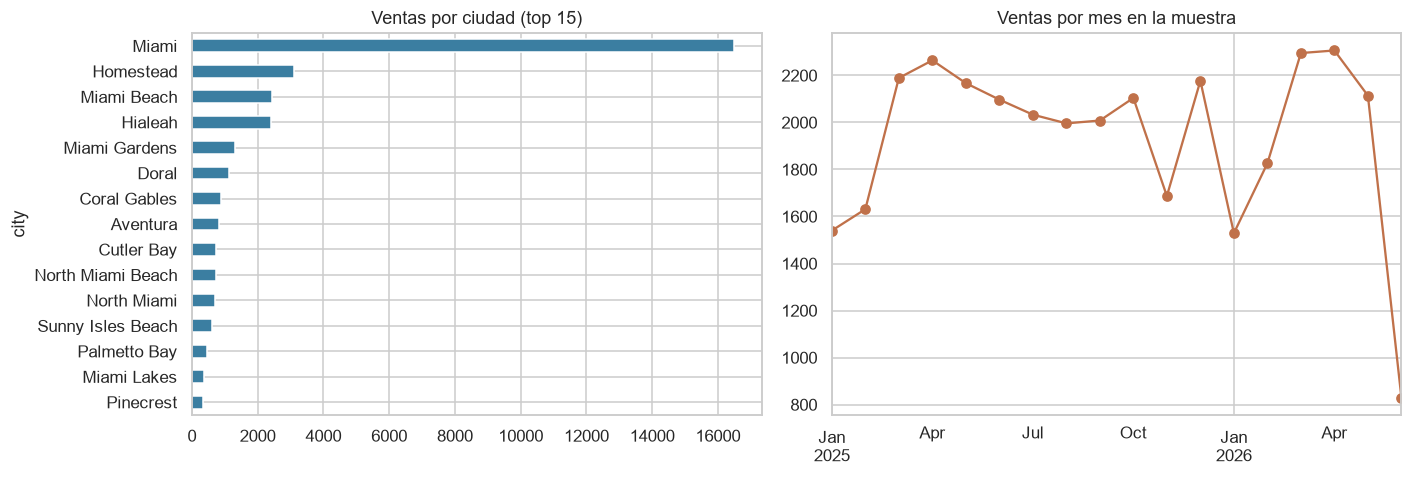

In [11]:
z = df.groupby("zip")["sold_price"].agg(["count", "median"])
print("Códigos postales:", len(z), "| con ≥30 ventas:", int((z["count"] >= 30).sum()), "| ventas en los 10 zips más frecuentes: %.0f%%" % (z["count"].nlargest(10).sum() / len(df) * 100))
c = df["city"].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
c.head(15).iloc[::-1].plot.barh(ax=axes[0], color="#3b7ea1"); axes[0].set(title="Ventas por ciudad (top 15)")
df.groupby(df["sale_date"].dt.to_period("M")).size().plot(ax=axes[1], marker="o", color="#c0714a"); axes[1].set(title="Ventas por mes en la muestra", xlabel="")
plt.tight_layout(); save("08_geografia_y_tiempo")

## 5. Viabilidad: ¿qué mide realmente cada precio?
Tres comprobaciones que condicionan el proyecto: (a) si `list_price` es un precio anunciado, (b) si `last_sold_price` es una venta histórica real y (c) si los atributos corresponden a la fecha de venta.

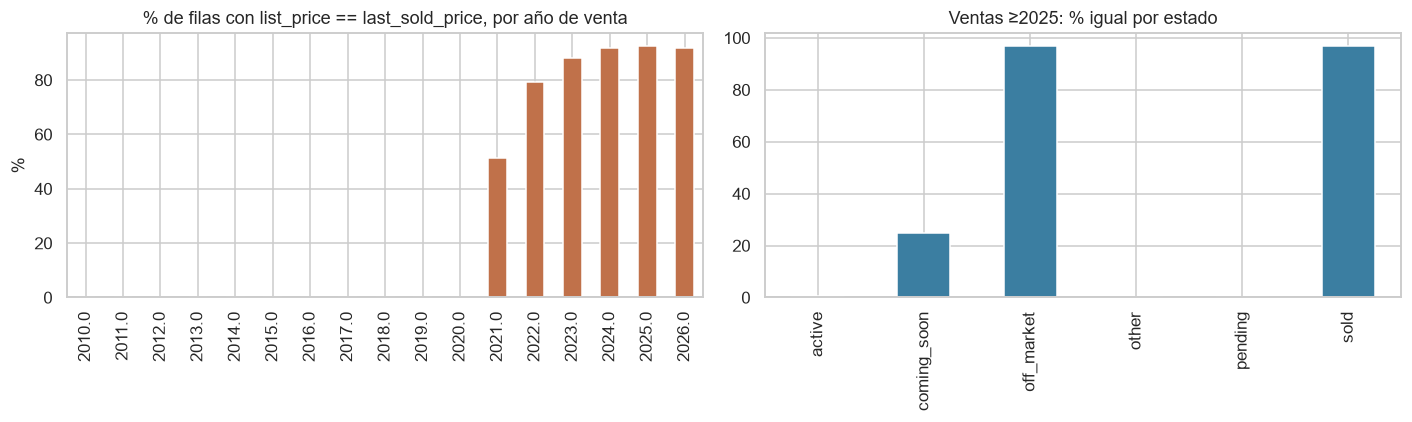

Ventas ≥2025 con status sold/off_market y list_price == last_sold_price: 96.9%


In [12]:
r = raw[(raw["last_sold_price"] > 0) & (raw["list_price"] > 0) & (raw["sale_year"] >= 2010)].copy()
r["igual"] = r["list_price"] == r["last_sold_price"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
r.groupby("sale_year")["igual"].mean().mul(100).plot.bar(ax=axes[0], color="#c0714a")
axes[0].set(title="% de filas con list_price == last_sold_price, por año de venta", xlabel="", ylabel="%")
rr = r[r["sale_year"] >= 2025]
rr.groupby("status")["igual"].mean().mul(100).plot.bar(ax=axes[1], color="#3b7ea1"); axes[1].set(title="Ventas ≥2025: % igual por estado", xlabel="")
plt.tight_layout(); save("09_list_price_igual_a_venta")
print("Ventas ≥2025 con status sold/off_market y list_price == last_sold_price: %.1f%%" %
      (rr[rr["status"].isin(["sold", "off_market"])]["igual"].mean() * 100))

**Conclusión (a).** En las ventas recientes de inmuebles `sold` y `off_market`, `list_price` coincide casi siempre con `last_sold_price`: no es un precio anunciado independiente, la fuente lo rellena con el precio de venta. Usarlo como variable de entrada sería una **fuga de información** (el modelo «vería» la respuesta) y además un usuario real no lo tiene. Solo los registros `active` tienen un precio de anuncio genuino, y son una minoría sin venta reciente asociada.

sale_year
≤1999      14.9
2000-09    19.2
2010-14    15.1
2015-19    20.1
2020-22    16.7
2023-24     8.4
2025-26     5.6

Inmuebles con year_built posterior al año de la venta: 9470 (el inmueble actual no existía en esa venta)


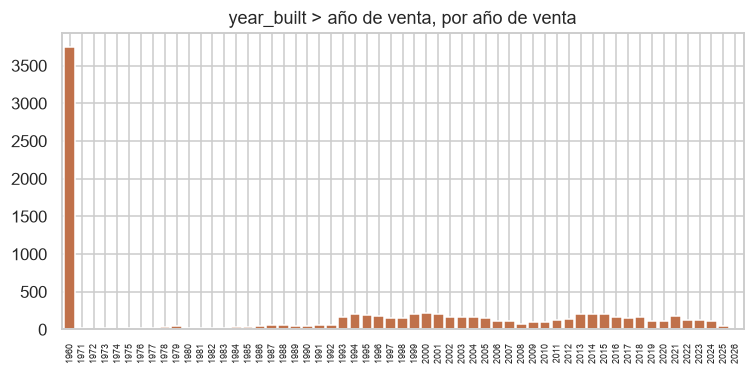

In [13]:
y = raw["sale_year"].dropna().astype(int)
bins = pd.cut(y, [1899, 1999, 2009, 2014, 2019, 2022, 2024, 2026], labels=["≤1999", "2000-09", "2010-14", "2015-19", "2020-22", "2023-24", "2025-26"])
print((bins.value_counts(normalize=True).sort_index() * 100).round(1).to_string())
d = raw[(raw["year_built"] > raw["sale_year"])]
print("\nInmuebles con year_built posterior al año de la venta:", len(d), "(el inmueble actual no existía en esa venta)")
fig, ax = plt.subplots(figsize=(8, 3.5))
d["sale_year"].astype(int).clip(lower=1960).value_counts().sort_index().plot.bar(ax=ax, color="#c0714a", width=.9)
ax.set(title="year_built > año de venta, por año de venta", xlabel=""); ax.tick_params(axis="x", labelsize=6); save("10_atributos_no_coinciden")

**Conclusión (b) y (c).** `last_sold_price` es el **último** precio de venta: la mayor parte son operaciones antiguas (más del 90 % anteriores a 2025), con fechas de relleno (`1900-01-01`). Los atributos (`sqft`, `beds`, `baths`, `year_built`) son una **foto actual del inmueble**, no su estado en la fecha de venta: cuanto más antigua la venta, más probable que haya reformas, ampliaciones o demoliciones (hay inmuebles construidos *después* de su «última venta»). Por eso se restringe a **ventas desde 2025**: el precio es de mercado reciente y la distancia entre venta y foto de atributos es de meses, no de décadas.

### Prueba empírica de viabilidad (regresión base con separación temporal)
Regresión lineal sobre `log(precio)` (solo numpy, sin dependencias extra). Se entrena con ventas de 2025 y se evalúa en las de 2026. Se compara el mismo modelo **con** y **sin** `list_price` para cuantificar la fuga. La mejora con `list_price` en una regresión lineal es moderada porque el ~8 % de filas con precio distinto (p. ej. anuncios `active`) distorsiona un único coeficiente; para el resto el valor se copia del objetivo. El código postal entra como media de `log(precio/sqft)` calculada **solo con entrenamiento** (sin fuga del test). MdAPE = error porcentual mediano. No es el modelo final: solo comprueba que los datos limpios contienen señal. Random Forest y Gradient Boosting llegan en la fase de modelado.

In [14]:
m = df.merge(raw[["id", "list_price"]], on="id", how="left")
cut = pd.Timestamp("2026-01-01")
tr, te = m[m["sale_date"] < cut].copy(), m[m["sale_date"] >= cut].copy()
print(f"train: {len(tr):,} (2025) | test: {len(te):,} (2026)")

gm = np.log(tr["sold_price"] / tr["sqft"]).mean()
zenc = np.log(tr["sold_price"] / tr["sqft"]).groupby(tr["zip"]).agg(["mean", "count"])
zenc["enc"] = (zenc["mean"] * zenc["count"] + gm * 10) / (zenc["count"] + 10)   # suavizado
types = sorted(m["property_type"].unique())

def design(d, use_list):
    X = pd.DataFrame({"const": 1.0, "log_sqft": np.log(d["sqft"]), "beds": d["beds"], "baths": d["baths"],
                      "age": d["property_age_at_sale"], "zip_enc": d["zip"].map(zenc["enc"]).fillna(gm),
                      "pool": d["pool"].astype(float), "waterfront": d["waterfront"].astype(float)}, index=d.index)
    for t in types[1:]: X["type_" + t] = (d["property_type"] == t).astype(float)
    if use_list: X["log_list"] = np.log(d["list_price"])
    return X

def run(use_list, name):
    tr_ok = tr[tr["list_price"] > 0] if use_list else tr
    te_ok = te[te["list_price"] > 0] if use_list else te
    beta = np.linalg.lstsq(design(tr_ok, use_list).values, np.log(tr_ok["sold_price"]).values, rcond=None)[0]
    p = np.exp(design(te_ok, use_list).values @ beta); t = te_ok["sold_price"].values
    ss = lambda a, b: 1 - ((a - b) ** 2).sum() / ((a - a.mean()) ** 2).sum()
    return ({"modelo": name, "n_test": len(t), "MAE_usd": round(np.abs(p - t).mean()), "MdAPE_%": round(np.median(np.abs(p - t) / t) * 100, 1),
             "R2_log": round(ss(np.log(t), np.log(p)), 3)}, te_ok.assign(pred=p))
(r1, pred_ok), (r2, _) = run(False, "Sin list_price (válido)"), run(True, "Con list_price (fuga)")
res = pd.DataFrame([r1, r2]); display(res)
tl = te[te["list_price"] > 0]
print("Test: %.1f%% de las filas tienen list_price == sold_price. Usar list_price COMO estimación da MdAPE = %.2f%%" %
      ((tl["list_price"] == tl["sold_price"]).mean() * 100, (np.abs(tl["list_price"] - tl["sold_price"]) / tl["sold_price"]).median() * 100))

train: 23,893 (2025) | test: 10,900 (2026)


,modelo,n_test,MAE_usd,MdAPE_%,R2_log
0,Sin list_price (válido),10900,337603,20.1,0.787
1,Con list_price (fuga),10895,270485,15.5,0.827


Test: 92.2% de las filas tienen list_price == sold_price. Usar list_price COMO estimación da MdAPE = 0.00%


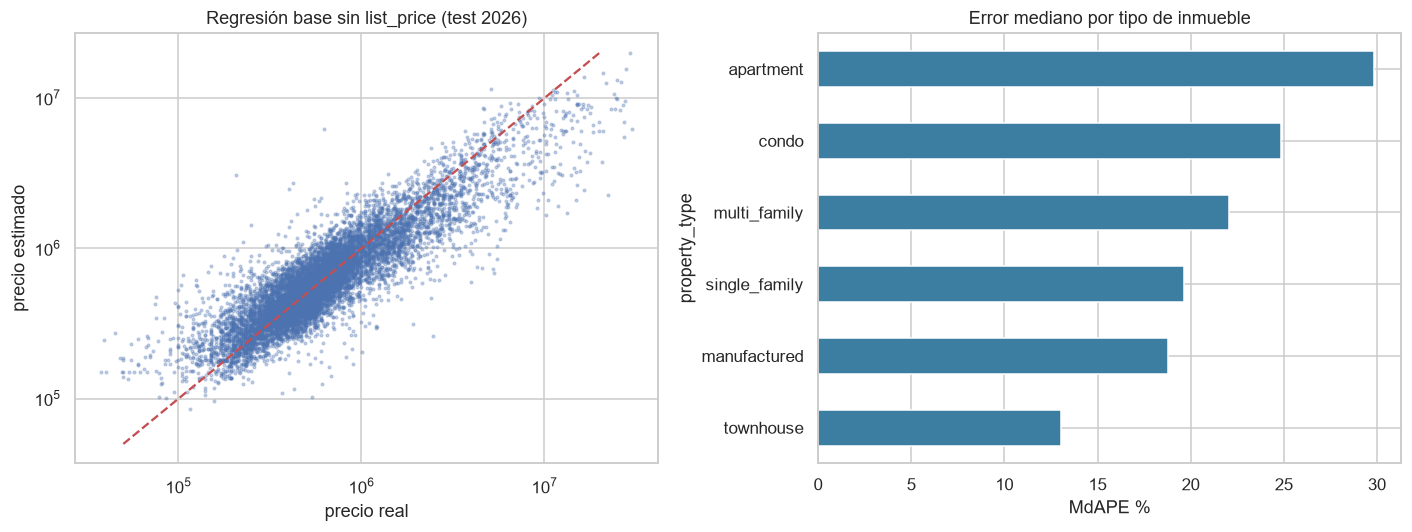

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
t, p = pred_ok["sold_price"], pred_ok["pred"]
axes[0].scatter(t, p, s=3, alpha=.3); lim = [5e4, 2e7]; axes[0].plot(lim, lim, "r--")
axes[0].set(xscale="log", yscale="log", xlabel="precio real", ylabel="precio estimado", title="Regresión base sin list_price (test 2026)")
(np.abs(p - t) / t * 100).groupby(pred_ok["property_type"]).median().sort_values().plot.barh(ax=axes[1], color="#3b7ea1")
axes[1].set(xlabel="MdAPE %", title="Error mediano por tipo de inmueble")
plt.tight_layout(); save("11_modelo_base")

## 6. Conclusión de viabilidad
HousingPulse AI **es viable con restricciones**: hay suficiente volumen reciente (decenas de miles de ventas desde 2025) y una regresión base sin fugas ya capta buena parte de la señal. Condiciones: usar solo ventas recientes, excluir `list_price`, tratar `last_sold_price` como «precio de la última venta» (no como valoración actual) y no ofrecer estimaciones en zonas con pocas ventas. Detalle en `docs/entregas/01_fuentes_eda_limpieza.md`.